# Guia Completo de Medidas de Dispersão: Teoria e Prática em Python

Este notebook reúne a explicação teórica sobre **medidas de dispersão** (ou variabilidade) e a implementação passo a passo em Python para validar os conceitos com exemplos numéricos e gráficos.

## 1. O que são Medidas de Dispersão e para que servem?

As **medidas de dispersão** são indicadores estatísticos que mostram o **quão espalhados ou concentrados** estão os dados de um conjunto em relação a uma medida central (geralmente a média aritmética).

Enquanto a média indica "onde" os dados estão centralizados, a dispersão mostra o "comportamento" deles ao redor desse centro:
* **Baixa dispersão:** os dados são parecidos, homogêneos e estão muito próximos da média.
* **Alta dispersão:** os dados são muito diferentes entre si e estão bem distantes da média.

### Para que servem na prática?
Elas servem para **avaliar a confiabilidade da média** e entender a **homogeneidade** de um grupo. Duas turmas podem ter a mesma média final (**7,0**), mas realidades opostas:
* **Turma A:** todos tiraram notas entre 6,8 e 7,2 (baixa dispersão, média muito representativa).
* **Turma B:** metade tirou 10 e a outra metade tirou 4 (alta dispersão, média esconde a desigualdade).

## 2. Principais Medidas de Dispersão

1. **Amplitude Total:** Diferença entre o maior e o menor valor do conjunto ($\text{Amplitude} = X_{\max} - X_{\min}$).
2. **Variância ($V$ ou $s^2$):** Média aritmética dos quadrados das diferenças (desvios) entre cada valor e a média. Como os desvios são elevados ao quadrado, a unidade de medida também fica ao quadrado.
3. **Desvio Padrão ($DP$ ou $s$ / $\sigma$):** Raiz quadrada da variância. Traz o resultado de volta para a mesma unidade dos dados originais (pontos, metros, reais).
4. **Coeficiente de Variação ($CV$):** Medida relativa que divide o desvio padrão pela média, expressa em porcentagem ($CV = \frac{DP}{\bar{x}} \times 100$). Permite comparar conjuntos com unidades ou médias diferentes.

## 3. Demonstração Passo a Passo em Python

Vamos utilizar o conjunto de **4 notas** de um aluno ao longo do ano: `[4, 7, 7, 10]`.

Primeiro, importamos as bibliotecas necessárias (`numpy` e `matplotlib`) e definimos nossos dados.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Conjunto de dados do exemplo
notas = np.array([4, 7, 7, 10])
avaliacoes = ['Nota 1', 'Nota 2', 'Nota 3', 'Nota 4']

print(f"Notas do aluno: {notas}")
print(f"Quantidade de avaliações (n): {len(notas)}")

Notas do aluno: [ 4  7  7 10]
Quantidade de avaliações (n): 4


### Passo 1: Média Aritmética ($\bar{x}$)

Antes de medir o espalhamento, calculamos o ponto central dos dados:
$$\bar{x} = \frac{4 + 7 + 7 + 10}{4} = 7,0$$

In [4]:
# Cálculo manual e via NumPy
media_manual = sum(notas) / len(notas)
media_np = np.mean(notas)

print(f"Somatório das notas: {sum(notas)} | Quantidade de notas: {len(notas)}")
print(f"Média Aritmética: {media_np:.2f}")

Somatório das notas: 28 | Quantidade de notas: 4
Média Aritmética: 7.00


### Passo 2: Amplitude Total

Subtraímos a menor nota da maior nota:
$$\text{Amplitude} = 10 - 4 = 6,0$$

In [ ]:
# Cálculo da amplitude (np.ptp = peak to peak)
amplitude = np.max(notas) - np.min(notas)


print(f"Maior nota: {np.max(notas)} | Menor nota: {np.min(notas)}")
print(f"Amplitude Total: {amplitude:.2f}")

Maior nota: 10 | Menor nota: 4
Amplitude Total: 6.00


### Passo 3: Variância ($V$)

Calculamos o desvio de cada nota em relação à média ($x_i - \bar{x}$), elevamos ao quadrado para eliminar sinais negativos e tiramos a média:
* **População completa (`ddof=0`):** divide por $n$ ($4$).
* **Amostra estatística (`ddof=1`):** divide por $n - 1$ ($3$) para corrigir o viés amostral.

In [7]:
# Detalhando cada desvio quadrado
desvios = notas - media_np
desvios_quadrados = desvios ** 2

for nome, nota, d, dq in zip(avaliacoes, notas, desvios, desvios_quadrados):
    print(f"{nome} ({nota}): desvio = {d:+.1f} | desvio² = {dq:.1f}")

# Variância Populacional vs Amostral
var_pop = np.var(notas, ddof=0)
var_amostral = np.var(notas, ddof=1)

print("-" * 45)
print(f"Variância Populacional (dividido por n=4):   {var_pop:.2f}")
print(f"Variância Amostral (dividido por n-1=3):   {var_amostral:.2f}")

Nota 1 (4): desvio = -3.0 | desvio² = 9.0
Nota 2 (7): desvio = +0.0 | desvio² = 0.0
Nota 3 (7): desvio = +0.0 | desvio² = 0.0
Nota 4 (10): desvio = +3.0 | desvio² = 9.0
---------------------------------------------
Variância Populacional (dividido por n=4):   4.50
Variância Amostral (dividido por n-1=3):   6.00


### Direfença:
#### 1. População Completa (ddof=0 — divide por \(n\))

    • Quando usar: Você tem todos os dados existentes do grupo que deseja estudar (ex: todas as 4 provas que um aluno fez no ano inteiro).  

    • Por que divide por \(n\): Como você conhece a média real e exata do grupo inteiro, não há margem de erro por falta de dados. Basta dividir a soma dos quadrados dos desvios pela quantidade total de itens (\(4\)).

#### 2. Amostra Estatística (ddof=1 — divide por \(n - 1\))  

    • Quando usar: Você tem apenas um recorte de um grupo muito maior (ex: 4 provas sorteadas entre 50 avaliações feitas ao longo de vários anos).  

    • O problema do viés amostral: Como você não tem todos os dados, não conhece a média verdadeira da população inteira. Você usa a média da própria amostra (\(\={x}\)) para calcular os desvios. Matematicamente, os dados de uma amostra sempre ficam mais "espremidos" em torno da sua própria média do que em torno da média real da população. Se você dividisse por \(n\), o desvio padrão pareceria menor do que realmente é.  

    • A solução (Correção de Bessel): Ao dividir por um número menor (\(n - 1\), ou seja, \(3\) em vez de \(4\)), o resultado da divisão fica ligeiramente maior. Esse aumento compensa os valores extremos que ficaram de fora da amostra.  

*Comparação no Exemplo (Notas: 4, 7, 7, 10)*  


|Critério	|População (ddof=0)	|Amostra (ddof=1)|
|-----|-----|-----|
|Divisor	|\(n = 4\)	|\(n - 1 = 3\)|
|Variância	|\(\frac{18}{4} = \mathbf{4,50}\)	|\(\frac{18}{3} = \mathbf{6,00}\)|
|Desvio Padrão	|\(\sqrt{4,5} \approx \mathbf{2,12}\)	|\(\sqrt{6,0} \approx \mathbf{2,45}\)|


*O que significa ddof no Python?*

    A sigla significa Delta Degrees of Freedom (Graus de Liberdade Delta). Ele diz ao Python quantos valores devem ser subtraídos do divisor \(n\) na fórmula:  
    • ddof=0: o divisor é \(n - 0 = n\).  
    • ddof=1: o divisor é \(n - 1\).  


### Passo 4: Desvio Padrão ($DP$)

Extraímos a raiz quadrada da variância para voltar à unidade original (pontos de nota):
$$DP = \sqrt{4,5} \approx 2,12$$

In [8]:
# Desvio Padrão Populacional vs Amostral
dp_pop = np.std(notas, ddof=0)
dp_amostral = np.std(notas, ddof=1)

print(f"Desvio Padrão Populacional: {dp_pop:.2f} pontos")
print(f"Desvio Padrão Amostral:     {dp_amostral:.2f} pontos")

Desvio Padrão Populacional: 2.12 pontos
Desvio Padrão Amostral:     2.45 pontos


### Passo 5: Coeficiente de Variação ($CV$)

Expressamos o desvio padrão como um percentual da média:
$$CV = \left(\frac{2,12}{7}\right) \times 100 \approx 30,3\%$$

Valores acima de **30%** geralmente indicam **alta dispersão** (conjunto heterogêneo).

In [9]:
cv_pop = (dp_pop / media_np) * 100
cv_amostral = (dp_amostral / media_np) * 100

print(f"Coeficiente de Variação (População): {cv_pop:.2f}%")
print(f"Coeficiente de Variação (Amostra):   {cv_amostral:.2f}%")

Coeficiente de Variação (População): 30.30%
Coeficiente de Variação (Amostra):   34.99%


## 4. Visualização Gráfica e Comparação de Turmas

Abaixo, geramos dois gráficos:
1. O comportamento das notas do nosso exemplo em relação à média e à faixa de $\pm 1$ desvio padrão.
2. A comparação prática mencionada na teoria entre a **Turma A** (homogênea) e a **Turma B** (heterogênea), ambas com média **7,0**.

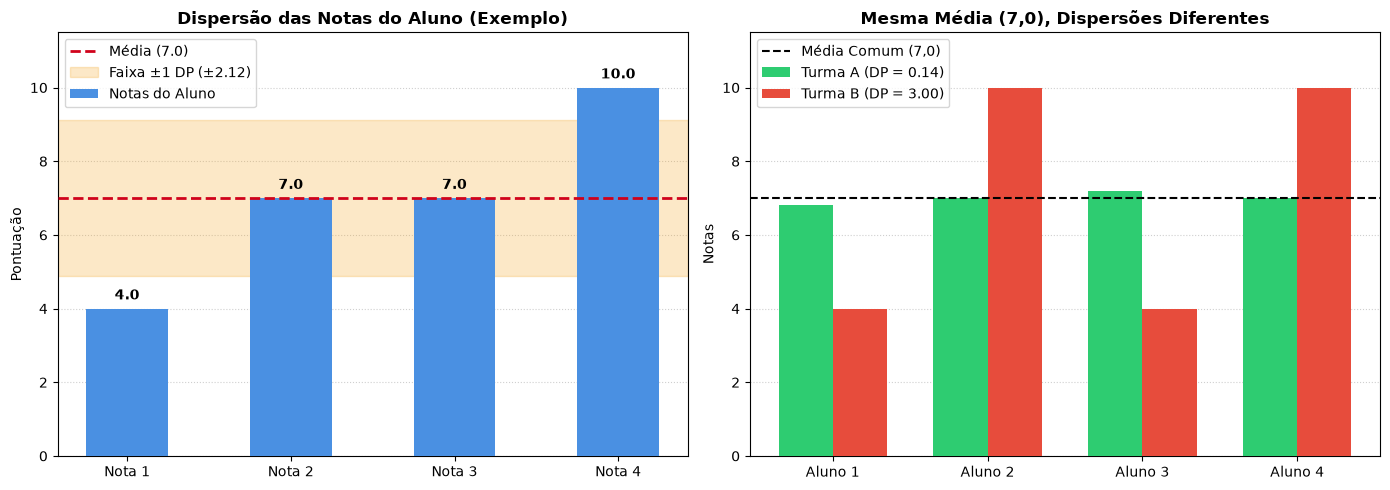

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: Exemplo do Aluno
bars = ax1.bar(avaliacoes, notas, color='#4A90E2', width=0.5, label='Notas do Aluno', zorder=3)
ax1.axhline(media_np, color='#D0021B', linestyle='--', linewidth=2, label=f'Média ({media_np:.1f})', zorder=4)
ax1.axhspan(media_np - dp_pop, media_np + dp_pop, color='#F5A623', alpha=0.25, label=f'Faixa ±1 DP (±{dp_pop:.2f})', zorder=2)

for bar in bars:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, yval + 0.25, f'{yval:.1f}', ha='center', fontweight='bold')

ax1.set_title('Dispersão das Notas do Aluno (Exemplo)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Pontuação')
ax1.set_ylim(0, 11.5)
ax1.grid(axis='y', linestyle=':', alpha=0.6, zorder=1)
ax1.legend(loc='upper left')

# Gráfico 2: Comparação Turma A vs Turma B (Mesma Média = 7.0)
turma_a = np.array([6.8, 7.0, 7.2, 7.0])
turma_b = np.array([4.0, 10.0, 4.0, 10.0])
alunos = ['Aluno 1', 'Aluno 2', 'Aluno 3', 'Aluno 4']
x = np.arange(len(alunos))
largura = 0.35

ax2.bar(x - largura/2, turma_a, largura, label=f'Turma A (DP = {np.std(turma_a):.2f})', color='#2ECC71', zorder=3)
ax2.bar(x + largura/2, turma_b, largura, label=f'Turma B (DP = {np.std(turma_b):.2f})', color='#E74C3C', zorder=3)
ax2.axhline(7.0, color='black', linestyle='--', linewidth=1.5, label='Média Comum (7,0)', zorder=4)

ax2.set_title('Mesma Média (7,0), Dispersões Diferentes', fontsize=12, fontweight='bold')
ax2.set_xticks(x)
ax2.set_xticklabels(alunos)
ax2.set_ylabel('Notas')
ax2.set_ylim(0, 11.5)
ax2.grid(axis='y', linestyle=':', alpha=0.6, zorder=1)
ax2.legend(loc='upper left')

plt.tight_layout()
plt.show()

#### Conclusão final do exemplo numérico (notas 4, 7, 7 e 10):

O conjunto apresenta alta dispersão e baixa homogeneidade, mostrando que a média 7,0 não representa um desempenho constante do aluno.


Para facilitar a visualização, veja o que cada resultado indica na prática:

• Consistência das notas: Apesar da média ser 7,0, o desvio padrão de 2,12 pontos (ou 2,45 pontos se tratado como amostra estatística, dividindo por \(n - 1\)) mostra que as notas fogem bastante do valor central.  

• Nível de variação (CV): O coeficiente de variação ficou em 30,3% (ou 35,0% no cálculo amostral). Na estatística, valores acima de 30% indicam alta dispersão, confirmando um desempenho irregular com muita oscilação entre notas baixas e altas.  

• Confiabilidade da média: A média sozinha esconderia o risco de reprovação nas avaliações mais baixas (nota 4), o que prova na prática por que as medidas de dispersão são essenciais para complementar a análise.  


Considerando uma média escolar padrão de 7,0 para aprovação, não há reprovação na Turma A, enquanto metade da Turma B seria reprovada, mesmo que ambas tenham exatamente a mesma média geral (7,0).  

Retomando os valores do primeiro exemplo para comparar a situação individual dos alunos:  

• Turma A (Notas entre 6,8 e 7,2):  

	• Situação: Todos os alunos ficam muito próximos da média 7,0 (baixa dispersão).

	• Risco de reprovação: Nulo (ou mínimo, se o corte for estritamente 7,0, apenas quem tirou 6,8 ou 6,9 ficaria de recuperação por décimos, mas ninguém está em situação crítica).

• Turma B (Metade tirou 10 e metade tirou 4):

	• Situação: Os dados estão nos extremos (alta dispersão).

	• Risco de reprovação: 50% da turma está reprovada (ou em recuperação crítica), pois metade dos alunos tirou nota 4,0, muito abaixo do corte necessário.
    

Por que esse exemplo é importante na estatística?

Ele mostra na prática que olhar apenas para a média da turma engana a tomada de decisão: se a escola avaliasse o desempenho apenas pela média geral (7,0), acharia que a Turma B está indo bem e não criaria aulas de reforço para os alunos com nota 4,0.